# Notebook 02 — Convolutional Autoencoder

## Chronology: architecture and normal-only pilot
This notebook begins Milestone 4. Development selection and the final benchmark
are **pending**. Notebook 01 and its artifacts remain unchanged. No autoencoder
official test evaluation has occurred. All numeric outputs below are from execution,
not checkpoint replay. Full local images/checkpoints remain outside Git.

An autoencoder learns an encoder $z=f_\theta(x)$ and decoder
$\hat{x}=g_\phi(z)$ that reproduce the input. Stride-two convolutions apply learned
local filters and halve spatial dimensions. The decoder doubles spatial dimensions
using bilinear interpolation and then learns convolutional filters. A linear 1x1
convolution creates the latent bottleneck; no skip connection bypasses it.

For a 256-square RGB input, an 8x32x32 bottleneck contains 8,192 values versus
196,608 input values (24-fold reduction in scalar count; this is not a bit-rate
or information-theoretic guarantee). L1 loss averages $|x-\hat{x}|$ over batch,
channels and pixels; MSE averages $(x-\hat{x})^2$ and emphasizes large residuals.
Training on fitting normals encourages reconstruction of normal structure.
Anomalies can nevertheless reconstruct well through shared local patterns or
excess capacity. Conversely, normal detail may reconstruct poorly. Blurring from
compression can produce residuals at normal edges; these are mechanisms to test,
not claims about unobserved final performance.

The predeclared development categories are bottle, cable, carpet and tile, chosen
for object/texture coverage without using official test performance. Bounded
ablation: shallow depth 3/latent 8/L1; depth 4; latent 2; latent 32; MSE.
One factor changes at a time. Combined loss, smoothing and a resolution change
require recorded development evidence first. Pilot: bottle, seed 2026, 256 pixels,
batch 16, Adam 0.001, three epochs, float32. No pretrained weights or augmentation.
Pilot epochs are a throughput check, not a selected final epoch budget.


In [1]:
from pathlib import Path
import sys, json, time, copy, traceback, subprocess
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from anomaly_detection.basic_cnn import seed_everything
from anomaly_detection.cnn_research import read_partition, require_fitting, load_resized
from anomaly_detection.data import sha256
from anomaly_detection.tracking import record
from anomaly_detection.autoencoder import ConvAutoencoder, reconstruction_loss, anomaly_map, image_scores
assert torch.cuda.is_available(), 'Pilot requires the existing CUDA environment'
torch.set_num_threads(4)
print(torch.__version__, torch.cuda.get_device_name(0))


Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


2.11.0+cu128 NVIDIA GeForce RTX 4060 Laptop GPU


## Actual architecture and scoring implementation
The following source is executed directly in the notebook. Channel-mean absolute
and squared residuals are separate candidate maps. A fixed top-1% mean aggregates each map into an image score; a maximum can be dominated by one noisy pixel.
Neither score is a probability. No smoothing is applied.

In [2]:
"""Scratch convolutional reconstruction baseline; RGB inputs/outputs in [0,1]."""
import math
import torch
from torch import nn
from torch.nn import functional as F


class ConvAutoencoder(nn.Module):
    """No skip connections: every reconstruction passes through the bottleneck.

    For depth=3, width=16, latent_channels=8 and 256-square inputs:
    encoder: B,3,256,256 -> B,16,128,128 -> B,32,64,64 -> B,64,32,32;
    bottleneck: B,8,32,32; decoder: B,32,64,64 -> B,16,128,128
    -> B,3,256,256. Bilinear upsampling followed by convolution avoids
    uneven transposed-convolution overlap. The final sigmoid bounds RGB.
    """
    def __init__(self, width=16, depth=3, latent_channels=8):
        super().__init__()
        if depth not in (3, 4) or width < 1 or latent_channels < 1:
            raise ValueError("Expected depth 3/4 and positive channel counts")
        self.divisor = 2 ** depth
        channels = [3] + [width * 2**i for i in range(depth)]
        layers = []
        for before, after in zip(channels, channels[1:]):
            layers.extend([nn.Conv2d(before, after, 3, 2, 1), nn.ReLU()])
        self.encoder = nn.Sequential(*layers)
        self.bottleneck = nn.Conv2d(channels[-1], latent_channels, 1)
        layers = []
        before = latent_channels
        for after in list(reversed(channels[1:-1])) + [3]:
            layers.extend([nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                           nn.Conv2d(before, after, 3, padding=1),
                           nn.Sigmoid() if after == 3 else nn.ReLU()])
            before = after
        self.decoder = nn.Sequential(*layers)

    def forward(self, images):
        if images.ndim != 4 or images.shape[1] != 3 or any(s % self.divisor for s in images.shape[-2:]):
            raise ValueError("Expected B,3,H,W with spatial dimensions divisible by 2**depth")
        return self.decoder(self.bottleneck(self.encoder(images)))


def reconstruction_loss(reconstructed, target, kind="l1"):
    if reconstructed.shape != target.shape:
        raise ValueError("Reconstruction and target shapes must match")
    if kind == "l1":
        return F.l1_loss(reconstructed, target)
    if kind == "mse":
        return F.mse_loss(reconstructed, target)
    raise ValueError("Expected l1 or mse; combined losses require development justification")


def anomaly_map(images, reconstructed, kind="absolute"):
    if images.shape != reconstructed.shape or images.ndim != 4:
        raise ValueError("Matching B,C,H,W tensors required")
    difference = images.float() - reconstructed.float()
    if kind == "absolute":
        return difference.abs().mean(1)
    if kind == "squared":
        return difference.square().mean(1)
    raise ValueError("Expected absolute or squared")


def image_scores(maps, fraction=.01):
    """Fixed top-1% mean by default; independent of image/pixel thresholds."""
    if maps.ndim != 3 or not 0 < fraction <= 1:
        raise ValueError("Expected B,H,W maps and fraction in (0,1]")
    flat = maps.flatten(1)
    return flat.topk(max(1, math.ceil(flat.shape[1]*fraction)), dim=1).values.mean(1)


In [3]:
config = dict(width=16, depth=3, latent_channels=8, loss='l1', resolution=256,
              batch_size=16, learning_rate=.001, epochs=3, seed=2026)
identifier = '02-pilot-shallow-bottle-s2026-v1'
compact = ROOT / 'reports/autoencoder'
local = ROOT / 'outputs/autoencoder' / identifier
compact.mkdir(parents=True, exist_ok=True)
local.mkdir(parents=True, exist_ok=True)
checkpoint = ROOT / 'checkpoints/autoencoder' / identifier / 'last.pt'
checkpoint.parent.mkdir(parents=True, exist_ok=True)
entry = dict(experiment_id=identifier+'-start', model_family='convolutional_autoencoder',
    categories=['bottle'], hypothesis='A scratch bottleneck model learns to reconstruct fitting normals; measure throughput before development.',
    preprocessing='PIL RGB bilinear 256x256, float32 /255', hyperparameters=config, seed=2026,
    environment=dict(torch=torch.__version__, gpu=torch.cuda.get_device_name(0),
      git_sha=subprocess.check_output(['git','rev-parse','HEAD'], cwd=ROOT,text=True).strip(),
      dirty=bool(subprocess.check_output(['git','status','--porcelain'], cwd=ROOT)),
      source_sha256=sha256(ROOT/'src/anomaly_detection/autoencoder.py'),
      lock_sha256=sha256(ROOT/'requirements.lock.txt'),
      partitions=json.loads((ROOT/'reports/dataset_validation.json').read_text())['partitions']),
    training={}, metrics={}, calibration={}, paths=dict(local=str(local.relative_to(ROOT))),
    interpretation='Throughput pilot only; no official test access.', decision='Measure before scaling', status='started')
record(ROOT/'experiments', entry)
seed_everything(config['seed'])
model = ConvAutoencoder(**{k:config[k] for k in ('width','depth','latent_channels')}).cuda()
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    x = torch.zeros(1,3,256,256,device='cuda')
    z = model.bottleneck(model.encoder(x))
    print('Input / latent / output:', x.shape, z.shape, model(x).shape)


ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
  )
  (bottleneck): Conv2d(64, 8, kernel_size=(1, 1), stride=(1, 1))
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='bilinear')
    (1): Conv2d(8, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='bilinear')
    (4): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Upsample(scale_factor=2.0, mode='bilinear')
    (7): Conv2d(16, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): Sigmoid()
  )
)
Trainable parameters: 31499


Input / latent / output: torch.Size([1, 3, 256, 256]) torch.Size([1, 8, 32, 32]) torch.Size([1, 3, 256, 256])


## Normal-only training loop
Only frozen fitting normals receive gradients. The reserved development normals
measure reconstruction each epoch. Calibration and official test data are not loaded.
All three epochs are retained; the pilot performs no checkpoint selection.

In [4]:
history = []
started = time.perf_counter()
try:
    fit_rows = read_partition('fit', 'bottle')
    require_fitting(fit_rows)
    dev_rows = read_partition('development', 'bottle')
    fit = load_resized(fit_rows, config['resolution']).cuda()
    dev = load_resized(dev_rows, config['resolution']).cuda()
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    shuffle = torch.Generator().manual_seed(config['seed'])
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(1, config['epochs']+1):
        tick = time.perf_counter()
        model.train()
        total = 0.
        for indices in torch.randperm(len(fit), generator=shuffle).split(config['batch_size']):
            batch = fit[indices.cuda()].float()/255
            optimizer.zero_grad(set_to_none=True)
            loss = reconstruction_loss(model(batch), batch, config['loss'])
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10., error_if_nonfinite=True)
            optimizer.step()
            total += loss.item()*len(batch)
        torch.cuda.synchronize()
        train_seconds = time.perf_counter()-tick
        model.eval()
        with torch.inference_mode():
            validation = sum(reconstruction_loss(model(b.float()/255), b.float()/255, config['loss']).item()*len(b)
                             for b in dev.split(config['batch_size']))/len(dev)
        torch.cuda.synchronize()
        row = dict(epoch=epoch, train_loss=total/len(fit), normal_development_loss=validation,
                   train_seconds=train_seconds, elapsed_seconds=time.perf_counter()-started,
                   peak_allocated_bytes=torch.cuda.max_memory_allocated(),
                   peak_reserved_bytes=torch.cuda.max_memory_reserved())
        history.append(row)
        pd.DataFrame(history).to_csv(compact/(identifier+'-history.csv'),index=False)
        print(json.dumps(row), flush=True)
    torch.save(dict(state_dict=model.state_dict(), configuration=config, category='bottle',
                    epoch=epoch, optimizer=optimizer.state_dict(), torch_rng=torch.get_rng_state(),
                    cuda_rng=torch.cuda.get_rng_state(), shuffle_rng=shuffle.get_state()), checkpoint)
    summary = dict(configuration=config, parameters=sum(p.numel() for p in model.parameters()),
                   fit_count=len(fit), development_count=len(dev), history=history,
                   wall_seconds=time.perf_counter()-started, checkpoint=str(checkpoint.relative_to(ROOT)),
                   checkpoint_sha256=sha256(checkpoint), checkpoint_bytes=checkpoint.stat().st_size)
    result = copy.deepcopy(entry)
    result.update(experiment_id=identifier+'-result', status='completed', metrics=summary,
                  decision='Pilot complete; development and freeze pending',
                  interpretation='See actual curves; no detection quality measured by reconstruction loss alone.')
    record(ROOT/'experiments', result)
    with (compact/(identifier+'-result.json')).open('x') as stream: json.dump(summary,stream,indent=2)
except BaseException as exc:
    (local/'failure.txt').write_text(traceback.format_exc())
    failed = copy.deepcopy(entry)
    failed.update(experiment_id=identifier+'-failure',status='failed',interpretation=str(exc),decision='Preserve and investigate')
    record(ROOT/'experiments',failed)
    raise


{"epoch": 1, "train_loss": 0.3268111354234267, "normal_development_loss": 0.3069065713113354, "train_seconds": 2.6236680000001797, "elapsed_seconds": 2.8244168999990507, "peak_allocated_bytes": 609729536, "peak_reserved_bytes": 901775360}


{"epoch": 2, "train_loss": 0.24193118796462104, "normal_development_loss": 0.10196471070089648, "train_seconds": 1.216956800000844, "elapsed_seconds": 4.102682699998695, "peak_allocated_bytes": 609729536, "peak_reserved_bytes": 901775360}


{"epoch": 3, "train_loss": 0.08909734242221937, "normal_development_loss": 0.08615253240831437, "train_seconds": 1.2079755999984627, "elapsed_seconds": 5.362124699999185, "peak_allocated_bytes": 609729536, "peak_reserved_bytes": 901775360}


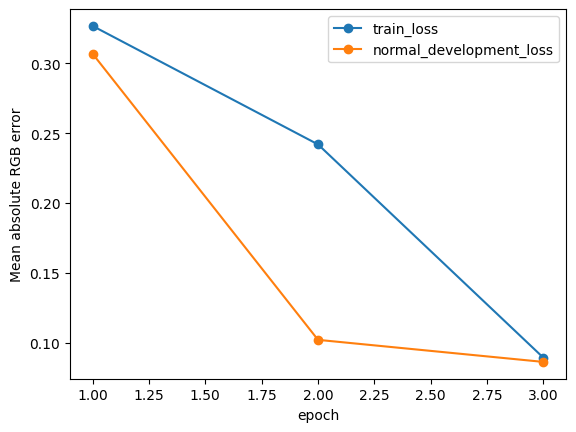

 epoch  train_loss  normal_development_loss  train_seconds  elapsed_seconds  peak_allocated_bytes  peak_reserved_bytes
     1    0.326811                 0.306907       2.623668         2.824417             609729536            901775360
     2    0.241931                 0.101965       1.216957         4.102683             609729536            901775360
     3    0.089097                 0.086153       1.207976         5.362125             609729536            901775360
Mean GPU training seconds per epoch: 1.6828667999998288
Peak allocated GiB: 0.5678548812866211
Illustrative 45-model, 20-epoch training seconds (before category-size adjustment): 1514.580119999846


In [5]:
frame = pd.DataFrame(history)
frame.plot(x='epoch', y=['train_loss','normal_development_loss'], marker='o', ylabel='Mean absolute RGB error')
plt.show()
print(frame.to_string(index=False))
print('Mean GPU training seconds per epoch:', frame.train_seconds.mean())
print('Peak allocated GiB:', frame.peak_allocated_bytes.max()/2**30)
print('Illustrative 45-model, 20-epoch training seconds (before category-size adjustment):',
      frame.train_seconds.mean()*45*20)


## Pilot reconstruction panels (local only)
First three development images in manifest order; no favorable image selection.
Display scales are fixed to [0,1]. These panels remain local under the dataset
retention policy; the public notebook retains the measured curves and tables.

In [6]:
with torch.inference_mode():
    originals = dev[:3].float()/255
    reconstructions = model(originals)
    absolute = anomaly_map(originals, reconstructions, 'absolute')
    squared = anomaly_map(originals, reconstructions, 'squared')
fig, axes = plt.subplots(3,4,figsize=(12,8))
for i in range(3):
    for j, values in enumerate([originals, reconstructions, absolute, squared]):
        a = values[i].cpu().numpy()
        axes[i,j].imshow(a.transpose(1,2,0) if a.ndim==3 else a, vmin=0,vmax=1)
        axes[i,j].axis('off')
for ax,title in zip(axes[0],['Normal original','Reconstruction','Absolute residual','Squared residual']): ax.set_title(title)
plt.tight_layout()
plt.show()


## Pending research and limits
The pilot does not measure detection or localization quality. Its three epochs
cannot establish convergence. A later append-only interpretation will use these
measured curves to set a bounded development epoch budget. Before final training,
publish an estimate adjusted for all category fitting counts, selected epoch count,
three seeds and measured memory. No all-category training has begun.

Development must compare the declared architectures, bottleneck capacities and
losses, plus absolute versus squared maps on fixed fitting-derived synthetic
probes and normal development evidence. Final policy, epochs, seeds, map and
aggregation must then be frozen before calibration/test evaluation. Image thresholds
will use the shared higher empirical 95th percentile of reserved normal scores,
with alarm strictly above threshold; pixel calibration needs its own rule.

All-category metrics, calibration counts/uncertainty, failure analysis and exact
stored Basic CNN comparisons are pending. No claim of improvement is made.
Experiment records: [append-only registry](../experiments/); pilot curves and
resource evidence: [reports](../reports/autoencoder/).
